# Download Subsetted ATL11 Data

This notebook spatially subsets and downloads ATL11 (ICESat-2 land-ice height) granules straight from NASA's Earthdata Cloud, for a region of interest you supply. 

Options to restrict download to specific reference ground tracks (RGTs) and/or pair tracks (PTs). 

Only the requested variables/rows are transferred over HTTPS; full granules are never downloaded.

*Using code from is2_subset.py originally written by Ben Smith, UW. 
Adapted by Bryony Freer, SIO.*



#### Prerequisites

- `is2_subset.py` present in the same directory as this notebook (or otherwise importable).
- A conda environment with `geopandas`, `h5py`, `fsspec`, `pyproj`, `shapely`, and `requests` installed.
- NASA Earthdata Login credentials: either a `~/.netrc` entry for `urs.earthdata.nasa.gov`, or the `$EARTHDATA_TOKEN` environment variable set.

In [ ]:
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
import importlib
import is2_subset
from is2_subset import *
importlib.reload(is2_subset)

## If needed, test earthdata authentication 
# token = earthdata_token()
# print("Earthdata authentication successful!")


<module 'is2_subset' from '/Users/bfreer/Documents/Code/IS2/test-code/is2_subset.py'>

#### **Select ROI for subsetting**

Load any vector file geopandas can read (shapefile, GeoPackage, GeoJSON, ...) and pick the polygon to subset ATL11 data to. `polygon_crs` is read directly from `gdf.crs`, so the ROI can be in any projection -- `read_subset()` reprojects internally as needed.

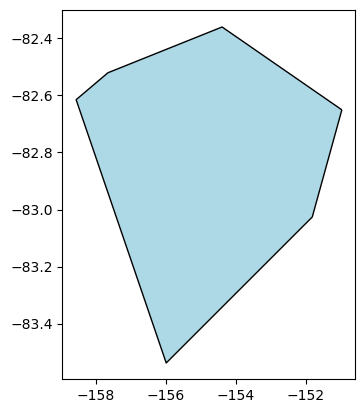

In [ ]:
# Read in shapefile for subsetting 
roi_path = f'/Users/bfreer/Documents/Scripps-Postdoc/Students/Elena-Dworak/data/Kamb-Elena-bb1.shp'
gdf = gpd.read_file(roi_path) 
gdf.plot(edgecolor="black", facecolor="lightblue")

# Select a single ROI to use in read_subset()
polygon = gdf.geometry.iloc[0]

#### **Select ATL11 variables to download**

Full list of ATL11 variables: https://nsidc.org/sites/default/files/icesat2_atl11_data_dict_v002_0.pdf

ATL11 User Guide: https://nsidc.org/sites/default/files/documents/user-guide/atl11-v007-userguide.pdf

Variable names are relative to each pair-track group (`pt1`/`pt2`/`pt3`) -- use a `/`-separated path for a variable nested in a subgroup, e.g. `ref_surf/dem_h` or `cycle_stats/tide_ocean`. A few variables live outside the pair-track groups entirely (granule-wide metadata, not per-point) -- give the full path from the file root for these, and `read_subset()` reads it once per granule rather than once per pair track.

Note: `is2_subset.py` falls back to a small built-in default set if `variables=` is omitted (`ref_pt`, `latitude`, `longitude`, `h_corr`, `h_corr_sigma`, `delta_time`, `quality_summary`, `cycle_number`). 

In [ ]:
# Variables to download
variables = [
    "ref_pt",
    "latitude",
    "longitude",
    "delta_time",
    "h_corr",
    "h_corr_sigma",
    "h_corr_sigma_systematic",
    "quality_summary",
    "cycle_number",
    "ref_surf/geoid_h",
    "ref_surf/dem_h",
    "cycle_stats/tide_ocean",
    "cycle_stats/dac",
    "ancillary_data/start_rgt",
]

#### **[Optional] Restrict the download to specific RGTs and/or pair tracks**

By default, `read_subset()` downloads every granule intersecting your ROI. The options below are different ways to build an `rgt_pt` list to restrict it instead -- pick **one** option (each cell overwrites `rgt_pt`).

**Option A: download everything (default)** -- no RGT/pair-track restriction

In [ ]:
rgt_pt = None

**Option B: select a subset of RGTs only** -- keeps all pair tracks for each listed RGT

In [ ]:
rgts_to_download = [1, 2, 3, 4, 5]  # Example RGTs; replace with actual RGTs of interest
rgt_pt = [(rgt, None) for rgt in rgts_to_download]

**Option C: select a subset of RGTs and PTs** -- manually specified

Each tuple is `(RGT, pt)`; `pt` can be `'pt1'`/`'pt2'`/`'pt3'`, or `None` to keep all three pair tracks for that RGT. 

Multiple tuples can share the same RGT (e.g. to request `pt2` and `pt3` but not `pt1`) -- they're combined automatically.

In [ ]:
# Manually specify RGT / PT subsets to download
rgt_pt = [
            (1, "pt1"),
            (2, "pt2"),
            (2, "pt3"), # Separate line for each PT if you want to download multiple PTs for the same RGT
            (3, "pt2"),
            (4, None),   # None gets all pts for that RGT
        ]

**Option D: select a subset of RGTs and PTs** -- parsed from a list

If you already have RGT/pt combos as strings like `"0001_2"` (RGT `0001`, pair track `2`), parse them into the `(RGT, pt)` tuples `read_subset()` expects.

In [ ]:
# Specify RGT / PT subsets to download from a string in format  ["0001_2", "0024_3"]
rgt_pt_list = ["0001_2", "0024_3"]  # your actual list
rgt_pt = [(int(s.split('_')[0]), f"pt{s.split('_')[1]}") for s in rgt_pt_list] # -> [(1, 'pt2'), (24, 'pt3')]

#### **Find and stream ATL11 subsets within ROI**

Searches NASA's CMR catalog for every ATL11 granule intersecting the ROI (restricted to `rgt_pt`, if set above), then streams just the requested variables/rows over HTTPS. This is the step that actually transfers data over the network, and takes the longest.
- `workers='auto'` reads granules in parallel, one worker per granule up to `max_workers`. 
- `verbose=True` prints progress per granule.

In [ ]:
# Read ATL11 subsets
results = read_subset(
    polygon=polygon,
    polygon_crs=gdf.crs,
    product="ATL11",
    version="007",
    variables=variables,
    rgt_pt=rgt_pt,
    workers='auto',
    max_workers=128,
    trim=True,
    verbose=True
)

#### **Save subsetted granules to disk**

Writes one `.h5` file per granule into `outdir`. 

- `flat=True` writes each file in the same layout as a raw ATL11 granule. 

- Omit it (or set `flat=False`) for the default layout, which nests everything under `/region_N/<granule>/<group>/` instead.

In [ ]:
# Download subsetted granules and write to disk
outdir = Path("/Users/bfreer/Documents/Code/IS2/test-code/data")
write_h5_by_granule(results, outdir=outdir, flat=True)